# Eight qubit GHZ entanglement - QPU 

## 1.0 Load Libraries 

In [1]:
from qiskit_ibm_runtime import QiskitRuntimeService
# for api token 
import keyring as k3

# set the qubit count
n_qubits = 8

# Get the API token from keyring
api_token = k3.get_password('ibm_quantum', 'api_token')


# set up your backend 
service = QiskitRuntimeService(channel="ibm_quantum", token=api_token)
backend = service.least_busy(
    operational=True, 
    simulator=False, 
    min_num_qubits=n_qubits
)

print(f"Using backend: {backend}")
print("Backend Loaded")


Using backend: <IBMBackend('ibm_sherbrooke')>
Backend Loaded


## 2.0 Create Circuit and Transpile 

In [3]:
from qiskit import QuantumCircuit, transpile

Quantum Circuit Created with 8 qubits


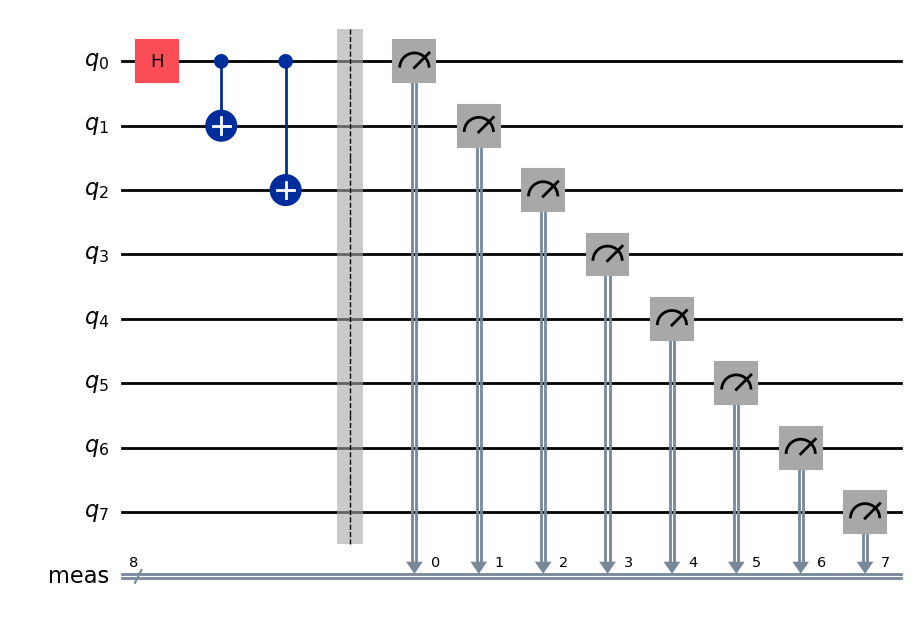

In [4]:
n = 8   # number of qubits
# create a quantum circuit with n qubits
qc = QuantumCircuit(n)  
print(f"Quantum Circuit Created with {n} qubits")

qc.h(0)  # apply Hadamard gate to qubit 0
qc.cx(0, 1)  # apply CNOT gate with control qubit 0 and target qubit 1
qc.cx(0, 2)  # apply CNOT gate with control qubit 0 and target qubit 2
qc.measure_all()  # measure all qubits

qc.draw('mpl')

Optimized Circuit Created


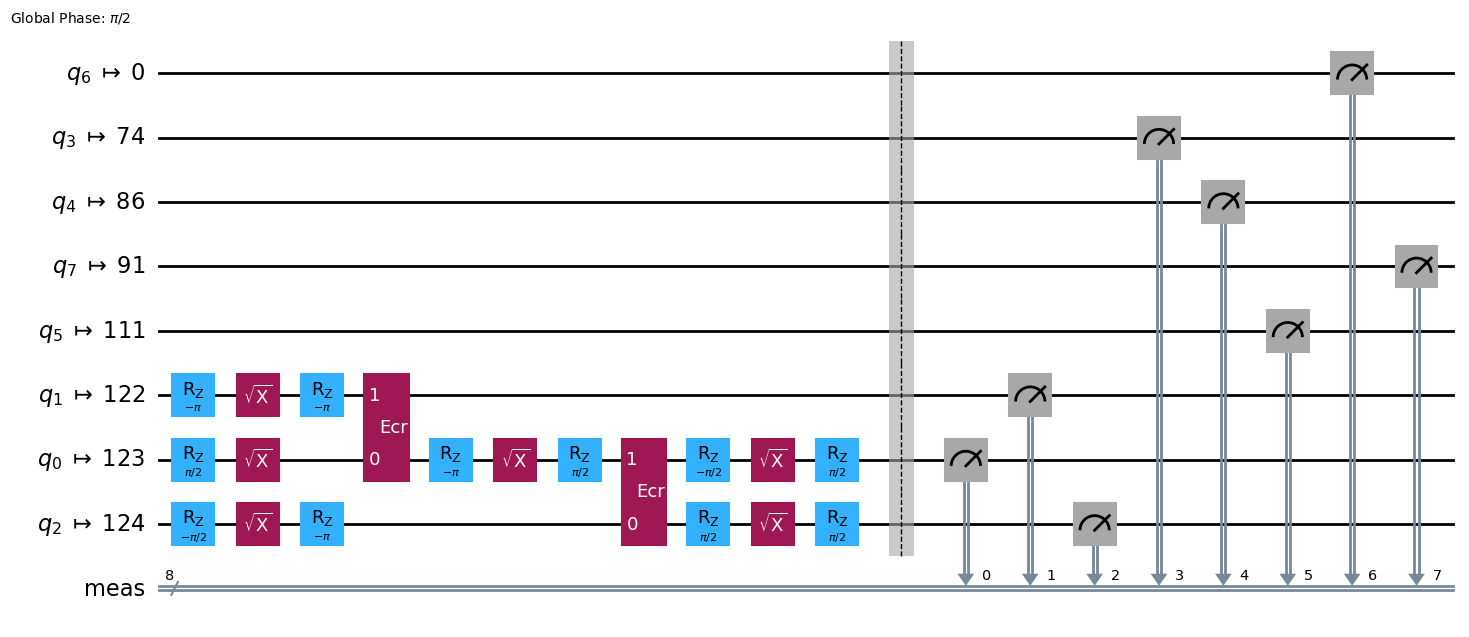

In [5]:
# transpile the circuit
transpiled_circuit = transpile(qc, backend=backend)

#construct  pub 
pub_qc_measurement = (transpiled_circuit) 

print("Optimized Circuit Created")
transpiled_circuit.draw('mpl')


## 3.0 Initiatize Sampler and Run 

In [6]:
from qiskit_ibm_runtime import SamplerV2

# Inaitialize the sampler
sampler = SamplerV2(backend)
job_qc_measurement = sampler.run([pub_qc_measurement], shots=1500)

# Extract results
result_qc_measurement = job_qc_measurement.result()
data_qc_measurement = result_qc_measurement[0].data
print("qc Measurement Results:")
print(data_qc_measurement)



qc Measurement Results:
DataBin(meas=BitArray(<shape=(), num_shots=1500, num_bits=8>))


## 4.0 Read result data 

In [7]:
bits = data_qc_measurement.meas
print('Shape: ', bits.shape)
print('num bits: ', bits.num_bits)
print('num shots: ', bits.num_shots)
print("array:\n", bits.array)


Shape:  ()
num bits:  8
num shots:  1500
array:
 [[5]
 [7]
 [5]
 ...
 [7]
 [7]
 [0]]


In [8]:
bitstrings = bits.get_bitstrings()
print("Bitstrings:", bitstrings)

Bitstrings: ['00000101', '00000111', '00000101', '00000000', '00000111', '00000111', '00000000', '00000000', '00000011', '00000000', '00000000', '00000000', '00000000', '00000000', '00000111', '00000111', '00000000', '00000000', '00000000', '00000111', '00000000', '00000111', '00000111', '00000000', '01000000', '00000111', '00000000', '00000000', '00000111', '00000000', '00000000', '00000000', '00000111', '00000000', '00000111', '00000000', '00000000', '00000000', '00000111', '00000111', '01000111', '00000111', '00000111', '00000111', '00000000', '00000000', '00000000', '00000000', '00000000', '00000111', '00000000', '00000111', '00000000', '00000000', '00000000', '00000000', '00000000', '00000111', '00000111', '00000111', '00000000', '00000111', '00000111', '00000000', '00000111', '00000000', '00000111', '00000000', '00000010', '00000111', '00000000', '00000000', '00000000', '00000111', '00000000', '00000000', '00000000', '00000111', '00100111', '00000000', '00000000', '00000000', '00

## 5.0 Save data for analysis 